In [3]:
from langgraph.graph import StateGraph, START, END
from  typing import TypedDict, Literal

In [11]:
class QState(TypedDict):

    a: int
    b: int
    c: int

    equation: str
    discriminant: float
    result: str

In [12]:
def showEq(state: QState):

    equation = f"{state['a']}x2{state['b']}x{state['c']}"

    return {'equation': equation}

In [13]:
def calcDisc(state: QState):

    discriminant = (state['b']**2) - (4*(state['a'])*(state['c']))
    return {'discriminant': discriminant}

In [14]:
def realRoot(state: QState):
    root1 = (-state["b"] + state["discriminant"]**0.5)/2*state["a"]
    root2 = (-state["b"] - state["discriminant"]**0.5)/2*state["a"]
    result = f"The roots are {root1} & {root2}"
    return {'result':result}

def norealRoot(state: QState):
    result = f"No real roots"
    return {'result':result}

def repRoot(state: QState):
    root = (-state["b"])/(2*state["a"])
    result = f"Only repeating root is {root}"
    return {'result': result}

def checkCondition(state:QState)-> Literal["realRoot", "norealRoot", "repRoot"]:
    if state['discriminant']>0:
        return 'realRoot'
    elif state['discriminant'] == 0:
        return "repRoot"
    else:
        return "norealRoot"


In [15]:
graph = StateGraph(QState)

graph.add_node('showEq', showEq)
graph.add_node('calcDisc', calcDisc)
graph.add_node('realRoot', realRoot)
graph.add_node('norealRoot', norealRoot)
graph.add_node('repRoot', repRoot)

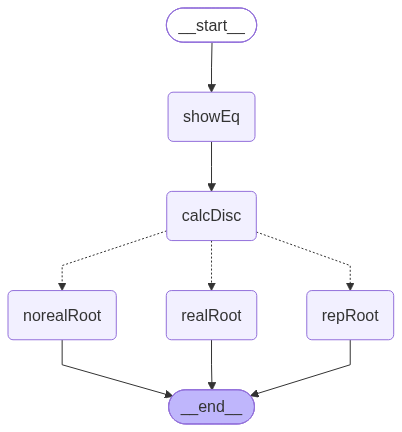

In [16]:
graph.add_edge(START, 'showEq')
graph.add_edge('showEq', 'calcDisc')

graph.add_conditional_edges('calcDisc', checkCondition)
graph.add_edge('realRoot', END)
graph.add_edge('norealRoot', END)
graph.add_edge('repRoot', END)
graph.compile()

In [17]:
workflow = graph.compile()

In [18]:
intState = {
    'a' : 4,
    'b' : -5,
    'c' : -4
}

fState = workflow.invoke(intState)
print(fState)



{'a': 4, 'b': -5, 'c': -4, 'equation': '4x2-5x-4', 'discriminant': 89, 'result': 'The roots are 28.867962264113206 & -8.867962264113206'}
